# Mobile-Former — 6-Class Chest X-Ray Classification

Mobile-Former (Chen et al., CVPR 2022) trained **from scratch** on the same combined chest X-ray dataset, split and training recipe as the SigLIP notebook (`SIG_VLM_PNEU_IMBALANCED`).

**Task:** multi-class (6 classes), cross-entropy, no class weights, no augmentation.
**Classes:** Bacterial Pneumonia, COVID, Lung_Opacity, Normal, Tuberculosis, Viral Pneumonia (alphabetical, from `LabelEncoder`).
**Sources:** COVID-19 Radiography Database, Chest X-Ray Pneumonia (bacterial only), TB Chest Radiography Database.

> Run on a GPU runtime (Kaggle: attach the three datasets, *Accelerator -> GPU*).

In [4]:
import os
import cv2
import math
import time
import torch
import random
import numpy as np
import pandas as pd
import seaborn as sns
import torch.nn as nn
from tqdm import tqdm
from pathlib import Path
import torch.optim as optim
from torchinfo import summary
from datetime import timedelta
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
from collections import defaultdict
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    matthews_corrcoef, confusion_matrix, classification_report, roc_curve, auc
)
from PIL import Image

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- hyper-parameters ----------------
# Training recipe is copied from the SigLIP notebook (batch 16, Adam, ExponentialLR 0.995, 25 epochs).
IMG_SIZE     = 224      # same input size as the SigLIP notebook
BATCH_SIZE   = 16
NUM_EPOCHS   = 25
LR           = 1e-5     # SigLIP notebook value. NOTE: Mobile-Former is trained from scratch here;
                        # if it under-fits, try 1e-3 (the value used in the PneumoniaMNIST notebook).
GAMMA        = 0.995    # ExponentialLR decay
WIDTH_MULT   = 0.5      # 1.0 = full Mobile-Former-294M channel widths from Table 1
NUM_TOKENS   = 6        # M, number of global tokens in Former
TOKEN_DIM    = 128      # d, token dimension (paper uses 192 for the 294M model)
SEED         = 42
NUM_WORKERS  = 2

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("device:", device)

device: cuda


In [6]:
dataset = Path(r"/kaggle/input/")

# Recursively search for a folder by name anywhere under base
def find_folder(base, folder_name, max_depth=5):
    base = Path(base)
    def _search(current, depth):
        if depth == 0:
            return None
        try:
            for entry in current.iterdir():
                if not entry.is_dir():
                    continue
                if entry.name == folder_name:
                    return entry
                result = _search(entry, depth - 1)
                if result:
                    return result
        except PermissionError:
            pass
        return None
    result = _search(base, max_depth)
    if result is None:
        raise FileNotFoundError(
            f"Could not find folder '{folder_name}' anywhere under {base}"
        )
    return result

covid_19   = find_folder(dataset, "COVID-19_Radiography_Dataset")
chest_xray = find_folder(dataset, "chest_xray")
tb_chest   = find_folder(dataset, "TB_Chest_Radiography_Database")

print(f"covid_19   = {covid_19}")
print(f"chest_xray = {chest_xray}")
print(f"tb_chest   = {tb_chest}")

covid_19   = /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset
chest_xray = /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray
tb_chest   = /kaggle/input/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset/TB_Chest_Radiography_Database


## Data Loading

In [7]:
class_mapping = defaultdict(list)

def append_file_names(directory, cls_name):
    """Append image file names from a directory to the class mapping."""
    directory = Path(directory)
    for f_name in os.listdir(directory):
        if f_name.lower().endswith((".jpeg", ".jpg", ".png")):
            class_mapping[cls_name].append(str(directory / f_name))

# COVID-19 dataset: each subfolder (COVID, Lung_Opacity, Normal, Viral Pneumonia)
# has an 'images' subdirectory
for covid19_class in [entry.name for entry in os.scandir(covid_19) if entry.is_dir()]:
    images_dir = covid_19 / covid19_class / 'images'
    if images_dir.exists():
        append_file_names(images_dir, covid19_class)
    else:
        # Some versions store images directly in the class folder
        append_file_names(covid_19 / covid19_class, covid19_class)

# Chest X-Ray dataset: only Bacterial Pneumonia (bacteria keyword in filename)
pneumonia_dirs = [chest_xray / "train" / "PNEUMONIA",
                  chest_xray / "test"  / "PNEUMONIA",
                  chest_xray / "val"   / "PNEUMONIA"]
for source_dir in pneumonia_dirs:
    if not source_dir.exists():
        print(f"Skipping (not found): {source_dir}")
        continue
    for filename in os.listdir(source_dir):
        if filename.lower().endswith((".jpeg", ".jpg", ".png")):
            if "bacteria" in filename.lower():
                class_mapping["Bacterial Pneumonia"].append(str(source_dir / filename))

# TB dataset
tb_dir = tb_chest / "Tuberculosis"
if tb_dir.exists():
    append_file_names(tb_dir, "Tuberculosis")
else:
    print(f"TB directory not found: {tb_dir}")

print("Classes found:", list(class_mapping.keys()))
print("Counts:", {k: len(v) for k, v in class_mapping.items()})

class_names = list(class_mapping.keys())
image_paths = []
labels = []

for class_name, file_paths in class_mapping.items():
    for file_path in tqdm(file_paths, desc=f"Processing {class_name}"):
        image_paths.append(file_path)
        labels.append(class_name)

Classes found: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia', 'Bacterial Pneumonia', 'Tuberculosis']
Counts: {'COVID': 3616, 'Lung_Opacity': 6012, 'Normal': 10192, 'Viral Pneumonia': 1345, 'Bacterial Pneumonia': 2780, 'Tuberculosis': 700}


Processing Tuberculosis: 100%|██████████| 700/700 [00:00<00:00, 2365844.32it/s]


## Train/Val/Test Split (80 / 10 / 10, stratified)

In [8]:
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels)
classes = label_encoder.classes_
num_classes = len(classes)

remaining_paths, test_paths, remaining_labels, test_labels = train_test_split(
    image_paths, labels_encoded, test_size=0.1, random_state=42, stratify=labels_encoded
)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    remaining_paths, remaining_labels, test_size=0.1111, random_state=42, stratify=remaining_labels
)

total_samples = len(labels_encoded)
print(f"Train: {len(train_paths)} ({len(train_paths)/total_samples*100:.2f}%)")
print(f"Val:   {len(val_paths)} ({len(val_paths)/total_samples*100:.2f}%)")
print(f"Test:  {len(test_paths)} ({len(test_paths)/total_samples*100:.2f}%)")
print("classes:", list(classes))
print("train class counts:", np.bincount(train_labels))

Train: 19715 (80.00%)
Val:   2465 (10.00%)
Test:  2465 (10.00%)
classes: [np.str_('Bacterial Pneumonia'), np.str_('COVID'), np.str_('Lung_Opacity'), np.str_('Normal'), np.str_('Tuberculosis'), np.str_('Viral Pneumonia')]
train class counts: [2224 2892 4810 8154  560 1075]


## Dataset & DataLoaders

The SigLIP notebook feeds 3-channel 224x224 images normalised with the SigLIP processor (bicubic resize to 224x224, rescale to [0, 1], mean 0.5 / std 0.5). The transform below reproduces exactly that preprocessing without needing `transformers`, so the Mobile-Former sees the same inputs. No augmentation, as in the original.

In [9]:
mf_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(),                                   # rescale to [0, 1]
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),  # SigLIP image mean / std
])

class ImageDataset(Dataset):
    def __init__(self, img_paths, img_labels, transform):
        self.img_paths = img_paths
        self.img_labels = img_labels
        self.transform = transform

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, index):
        img = cv2.imread(str(self.img_paths[index]))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(img)
        return self.transform(pil_img), self.img_labels[index]

train_dataset = ImageDataset(train_paths, train_labels, mf_transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_dataset = ImageDataset(val_paths, val_labels, mf_transform)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True)
test_dataset = ImageDataset(test_paths, test_labels, mf_transform)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True)

## Mobile-Former Model

Model code is unchanged from the PneumoniaMNIST notebook (parallel MobileNet + Former, two-way light-weight cross-attention bridge, dynamic ReLU). Only the instantiation changes: `in_chans=3`, `num_classes=6`.

In [10]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def make_divisible(v, divisor=8, min_value=8):
    new_v = max(min_value, int(v + divisor / 2) // divisor * divisor)
    if new_v < 0.9 * v:
        new_v += divisor
    return new_v


class HSwish(nn.Module):
    def forward(self, x):
        return x * F.relu6(x + 3.0) / 6.0


# ---------------------------------------------------------------
# Dynamic ReLU (spatial-shared). Parameters come from Former's first token.
#   y_c = max_k ( a_k,c * x_c + b_k,c ),  k = 1, 2
# ---------------------------------------------------------------
class DyReLU(nn.Module):
    def __init__(self, channels, k=2, lambda_a=1.0, lambda_b=0.5):
        super().__init__()
        self.channels, self.k = channels, k
        self.lambda_a, self.lambda_b = lambda_a * 2.0, lambda_b
        # initial slopes: a1 = 1, a2 = 0 -> behaves like ReLU at init
        self.register_buffer("init_a", torch.tensor([1.0] + [0.0] * (k - 1)))
        self.register_buffer("init_b", torch.zeros(k))

    @property
    def n_params(self):
        return 2 * self.k * self.channels

    def forward(self, x, theta):
        # theta: (B, 2*k*C) raw output of the theta MLP
        B, C = theta.shape[0], self.channels
        t = 2.0 * torch.sigmoid(theta) - 1.0               # in (-1, 1)
        t = t.view(B, C, 2 * self.k)
        a = (t[..., : self.k] - 0.5) * self.lambda_a + self.init_a   # (B, C, k)
        b = t[..., self.k:] * self.lambda_b + self.init_b            # (B, C, k)
        a = a.view(B, C, self.k, 1, 1)
        b = b.view(B, C, self.k, 1, 1)
        out = x.unsqueeze(2) * a + b                       # (B, C, k, H, W)
        return out.max(dim=2)[0]


# ---------------------------------------------------------------
# Mobile sub-block: inverted bottleneck with dynamic ReLU (Fig. 3)
# ---------------------------------------------------------------
class MobileBlock(nn.Module):
    def __init__(self, inp, exp, oup, stride, token_dim, k=2):
        super().__init__()
        self.use_res = (stride == 1 and inp == oup)
        self.pw1 = nn.Conv2d(inp, exp, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(exp)
        self.act1 = DyReLU(exp, k)
        self.dw = nn.Conv2d(exp, exp, 3, stride, 1, groups=exp, bias=False)
        self.bn2 = nn.BatchNorm2d(exp)
        self.act2 = DyReLU(exp, k)
        self.pw2 = nn.Conv2d(exp, oup, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(oup)
        # theta: two MLP layers on the first global token -> parameters for both DyReLUs
        n = self.act1.n_params + self.act2.n_params
        self.theta = nn.Sequential(
            nn.Linear(token_dim, token_dim // 4), nn.ReLU(inplace=True),
            nn.Linear(token_dim // 4, n))
        self.n1 = self.act1.n_params

    def forward(self, x, z1):
        th = self.theta(z1)
        th1, th2 = th[:, : self.n1], th[:, self.n1:]
        out = self.act1(self.bn1(self.pw1(x)), th1)
        out = self.act2(self.bn2(self.dw(out)), th2)
        out = self.bn3(self.pw2(out))
        return x + out if self.use_res else out


# ---------------------------------------------------------------
# Mobile -> Former : light-weight cross attention (Eq. 1)
#   Query = z W^Q (Former side), Key = Value = x (NO projections on Mobile side)
#   heads concatenated, then W^O maps C -> d
# ---------------------------------------------------------------
class Mobile2Former(nn.Module):
    def __init__(self, C, d, heads=2):
        super().__init__()
        assert C % heads == 0
        self.h, self.C = heads, C
        self.q = nn.Linear(d, C)          # W^Q  (per-head matrices stacked)
        self.o = nn.Linear(C, d)          # W^O
        self.scale = (C // heads) ** -0.5

    def forward(self, x, z):
        B, C, H, W = x.shape
        M = z.shape[1]
        q = self.q(z).view(B, M, self.h, C // self.h).transpose(1, 2)           # B,h,M,C/h
        kv = x.flatten(2).transpose(1, 2).reshape(B, H * W, self.h, C // self.h).transpose(1, 2)  # B,h,HW,C/h
        attn = (q @ kv.transpose(-1, -2)) * self.scale                          # B,h,M,HW
        attn = attn.softmax(-1)
        out = (attn @ kv).transpose(1, 2).reshape(B, M, C)                      # B,M,C
        return self.o(out)


# ---------------------------------------------------------------
# Mobile <- Former : light-weight cross attention (Eq. 2)
#   Query = x (NO projection), Key = z W^K, Value = z W^V
# ---------------------------------------------------------------
class Former2Mobile(nn.Module):
    def __init__(self, C, d, heads=2):
        super().__init__()
        assert C % heads == 0
        self.h, self.C = heads, C
        self.k = nn.Linear(d, C)          # W^K
        self.v = nn.Linear(d, C)          # W^V
        self.scale = (C // heads) ** -0.5
        self.last_attn = None

    def forward(self, x, z):
        B, C, H, W = x.shape
        M = z.shape[1]
        q = x.flatten(2).transpose(1, 2).reshape(B, H * W, self.h, C // self.h).transpose(1, 2)  # B,h,HW,C/h
        k = self.k(z).view(B, M, self.h, C // self.h).transpose(1, 2)           # B,h,M,C/h
        v = self.v(z).view(B, M, self.h, C // self.h).transpose(1, 2)
        attn = ((q @ k.transpose(-1, -2)) * self.scale).softmax(-1)             # B,h,HW,M
        self.last_attn = attn.detach()
        out = (attn @ v).transpose(1, 2).reshape(B, H * W, C)                   # B,HW,C
        return out.transpose(1, 2).reshape(B, C, H, W)


# ---------------------------------------------------------------
# Former sub-block: standard transformer block (MHA + FFN, expansion 2, post-LN)
# ---------------------------------------------------------------
class FormerBlock(nn.Module):
    def __init__(self, d, heads=4, ffn_ratio=2, dropout=0.0):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.ln1 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, d * ffn_ratio), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(d * ffn_ratio, d))
        self.ln2 = nn.LayerNorm(d)

    def forward(self, z):
        z = self.ln1(z + self.attn(z, z, z, need_weights=False)[0])
        z = self.ln2(z + self.ffn(z))
        return z


# ---------------------------------------------------------------
# One Mobile-Former block = Mobile->Former, Former, Mobile, Mobile<-Former
# For the downsample variant (stride 2) the bridge Mobile->Former sees an
# average-pooled copy of x to keep the cost low.
# ---------------------------------------------------------------
class MobileFormerBlock(nn.Module):
    def __init__(self, inp, exp, oup, stride, d, heads_bridge=2, heads_former=4, dropout=0.0):
        super().__init__()
        self.stride = stride
        self.m2f = Mobile2Former(inp, d, heads_bridge)
        self.ln_m2f = nn.LayerNorm(d)
        self.former = FormerBlock(d, heads_former, 2, dropout)
        self.mobile = MobileBlock(inp, exp, oup, stride, d)
        self.f2m = Former2Mobile(oup, d, heads_bridge)

    def forward(self, x, z):
        x_in = F.avg_pool2d(x, 2) if self.stride == 2 else x
        z = self.ln_m2f(z + self.m2f(x_in, z))     # Mobile -> Former
        z = self.former(z)                         # Former
        x = self.mobile(x, z[:, 0])                # Mobile (DyReLU params from first token)
        x = x + self.f2m(x, z)                     # Mobile <- Former
        return x, z


# ---------------------------------------------------------------
# Full network
# ---------------------------------------------------------------
class MobileFormer(nn.Module):
    """
    Mobile-Former following Table 1 (294M model) of the paper.
    width_mult scales all channel counts, num_tokens/token_dim set the Former.
    """
    # (exp, out, stride)   -- from Table 1, stages 2-5
    CFG = [
        (96, 24, 2), (96, 24, 1),
        (144, 48, 2), (192, 48, 1),
        (288, 96, 2), (384, 96, 1), (576, 128, 1), (768, 128, 1),
        (768, 192, 2), (1152, 192, 1), (1152, 192, 1),
    ]

    def __init__(self, in_chans=1, num_classes=2, width_mult=0.5, num_tokens=6,
                 token_dim=128, head_dim=512, dropout=0.2, former_dropout=0.0):
        super().__init__()
        w = lambda c: make_divisible(c * width_mult)
        self.num_tokens, self.token_dim = num_tokens, token_dim

        # learnable, randomly initialised global tokens
        self.tokens = nn.Parameter(torch.randn(num_tokens, token_dim) * 0.02)

        stem_c = w(16)
        self.stem = nn.Sequential(nn.Conv2d(in_chans, stem_c, 3, 2, 1, bias=False),
                                  nn.BatchNorm2d(stem_c), HSwish())
        # lite bottleneck: 3x3 depthwise (expands x2) + pointwise squeeze
        self.bneck = nn.Sequential(
            nn.Conv2d(stem_c, stem_c * 2, 3, 1, 1, groups=stem_c, bias=False),
            nn.BatchNorm2d(stem_c * 2), nn.ReLU(inplace=True),
            nn.Conv2d(stem_c * 2, stem_c, 1, bias=False), nn.BatchNorm2d(stem_c))

        blocks, inp = [], stem_c
        for exp, out, s in self.CFG:
            blocks.append(MobileFormerBlock(inp, w(exp), w(out), s, token_dim,
                                            dropout=former_dropout))
            inp = w(out)
        self.blocks = nn.ModuleList(blocks)

        last_c = w(1152)
        self.last = nn.Sequential(nn.Conv2d(inp, last_c, 1, bias=False),
                                  nn.BatchNorm2d(last_c), HSwish())
        self.head = nn.Sequential(
            nn.Linear(last_c + token_dim, head_dim), HSwish(),
            nn.Dropout(dropout), nn.Linear(head_dim, num_classes))
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out")
        elif isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x):
        B = x.shape[0]
        z = self.tokens.unsqueeze(0).expand(B, -1, -1)
        x = self.stem(x)
        x = x + self.bneck(x)
        for blk in self.blocks:
            x, z = blk(x, z)
        x = self.last(x).mean((2, 3))               # global average pooling
        feat = torch.cat([x, z[:, 0]], dim=1)       # concat with first global token
        return self.head(feat)

In [11]:
set_seed(SEED)
model = MobileFormer(in_chans=3, num_classes=num_classes, width_mult=WIDTH_MULT,
                     num_tokens=NUM_TOKENS, token_dim=TOKEN_DIM).to(device)
summary(model, input_size=(1, 3, IMG_SIZE, IMG_SIZE))

# FLOP estimate
try:
    from torch.utils.flop_counter import FlopCounterMode
    model.eval()
    with FlopCounterMode(display=False) as fc:
        model(torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device))
    print(f"Approx. MAdds per image: {fc.get_total_flops()/2/1e6:.1f} M @ {IMG_SIZE}x{IMG_SIZE}")
except Exception as e:
    print("FLOP counter unavailable:", e)

Approx. MAdds per image: 92.7 M @ 224x224


## Metrics Function

In [12]:
def custom_metrics(y_pred, y_true, loss):
    y_pred_classes = torch.argmax(y_pred, dim=1)
    y_true_numpy = y_true.cpu().numpy()
    y_pred_classes_numpy = y_pred_classes.cpu().numpy()
    accuracy = accuracy_score(y_true_numpy, y_pred_classes_numpy)
    precision = precision_score(y_true_numpy, y_pred_classes_numpy, average='weighted')
    recall = recall_score(y_true_numpy, y_pred_classes_numpy, average='weighted')
    f1 = f1_score(y_true_numpy, y_pred_classes_numpy, average='weighted')
    cm = confusion_matrix(y_true_numpy, y_pred_classes_numpy)
    tn = cm[0, 0]
    fp = cm[0, 1:].sum()
    fn = cm[1:, 0].sum()
    tp = cm[1:, 1:].sum()
    specificity = tn / (tn + fp)
    sensitivity = tp / (tp + fn)
    mcc = matthews_corrcoef(y_true_numpy, y_pred_classes_numpy)
    auc_scores = []
    for class_idx in range(y_pred.shape[1]):
        class_y_true = (y_true_numpy == class_idx).astype(np.float32)
        class_y_pred = y_pred[:, class_idx].cpu().numpy()
        auc_score = roc_auc_score(class_y_true, class_y_pred)
        auc_scores.append(auc_score)
    auc_avg = np.mean(auc_scores)
    return {
        "loss": loss, "accuracy": accuracy, "precision": precision,
        "recall": recall, "f1_score": f1, "specificity": specificity,
        "sensitivity": sensitivity, "mcc": mcc, "auc": auc_avg,
    }

## Training

In [13]:
criterion = torch.nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=GAMMA)

metric_names = ["loss", "accuracy", "precision", "recall", "f1_score",
                "specificity", "sensitivity", "mcc", "auc"]
train_metrics_history = {m: [] for m in metric_names}
val_metrics_history = {m: [] for m in metric_names}

num_epochs = NUM_EPOCHS
total_training_time = 0.0
total_validation_time = 0.0

for epoch in range(num_epochs):
    start_time = time.time()
    model.train()
    total_loss = 0.0
    all_predictions = []
    all_targets = []

    for data, targets in tqdm(train_loader, desc=f"Training - Epoch [{epoch+1}/{num_epochs}]"):
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        all_predictions.extend(outputs.detach().cpu().numpy())
        all_targets.extend(targets.detach().cpu().numpy())

    end_time = time.time()
    total_training_time += end_time - start_time

    average_loss = total_loss / len(train_loader)
    all_predictions = np.array(all_predictions)
    all_targets = np.array(all_targets)
    train_metrics = custom_metrics(torch.tensor(all_predictions), torch.tensor(all_targets), average_loss)
    for m in metric_names:
        train_metrics_history[m].append(train_metrics[m])
    line = "Train - " + ", ".join([f"{k}: {v:.4f}" for k, v in train_metrics.items()])
    print(line)

    # Validation
    model.eval()
    total_loss = 0.0
    all_predictions = []
    all_targets = []
    val_start = time.time()
    with torch.no_grad():
        for data, targets in tqdm(val_loader, desc=f"Validation - Epoch [{epoch+1}/{num_epochs}]"):
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            total_loss += loss.item()
            all_predictions.extend(outputs.detach().cpu().numpy())
            all_targets.extend(targets.detach().cpu().numpy())
    total_validation_time += time.time() - val_start

    average_loss = total_loss / len(val_loader)
    all_predictions = np.array(all_predictions)
    all_targets = np.array(all_targets)
    val_metrics = custom_metrics(torch.tensor(all_predictions), torch.tensor(all_targets), average_loss)
    for m in metric_names:
        val_metrics_history[m].append(val_metrics[m])
    line = "Val   - " + ", ".join([f"{k}: {v:.4f}" for k, v in val_metrics.items()])
    print(line)

    scheduler.step()

print(f"\nTotal Training Time: {str(timedelta(seconds=int(total_training_time)))}")
print(f"Total Validation Time: {str(timedelta(seconds=int(total_validation_time)))}")

torch.save(model.state_dict(), "mobileformer_final.pt")   # final-epoch weights (no best-checkpoint selection, as in the SigLIP notebook)

Training - Epoch [1/25]: 100%|██████████| 1233/1233 [38:14<00:00,  1.86s/it]


Train - loss: 1.2993, accuracy: 0.5047, precision: 0.4681, recall: 0.5047, f1_score: 0.4473, specificity: 0.2702, sensitivity: 0.9531, mcc: 0.2679, auc: 0.7326


Validation - Epoch [1/25]: 100%|██████████| 155/155 [04:18<00:00,  1.67s/it]
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Val   - loss: 1.0451, accuracy: 0.5988, precision: 0.5605, recall: 0.5988, f1_score: 0.5462, specificity: 0.6367, sensitivity: 0.9163, mcc: 0.4316, auc: 0.8188


Training - Epoch [2/25]: 100%|██████████| 1233/1233 [02:31<00:00,  8.16it/s]


Train - loss: 0.9937, accuracy: 0.6160, precision: 0.6133, recall: 0.6160, f1_score: 0.5891, specificity: 0.6853, sensitivity: 0.9156, mcc: 0.4592, auc: 0.8317


... (90 outputs left out)

Training - Epoch [25/25]: 100%|██████████| 1233/1233 [02:30<00:00,  8.20it/s]


Train - loss: 0.3508, accuracy: 0.8624, precision: 0.8613, recall: 0.8624, f1_score: 0.8610, specificity: 0.8678, sensitivity: 0.9778, mcc: 0.8112, auc: 0.9556


Validation - Epoch [25/25]: 100%|██████████| 155/155 [00:11<00:00, 13.02it/s]

Val   - loss: 0.4838, accuracy: 0.8211, precision: 0.8208, recall: 0.8211, f1_score: 0.8207, specificity: 0.8381, sensitivity: 0.9707, mcc: 0.7565, auc: 0.9493

Total Training Time: 1:38:20
Total Validation Time: 0:09:07


## Plot Metrics

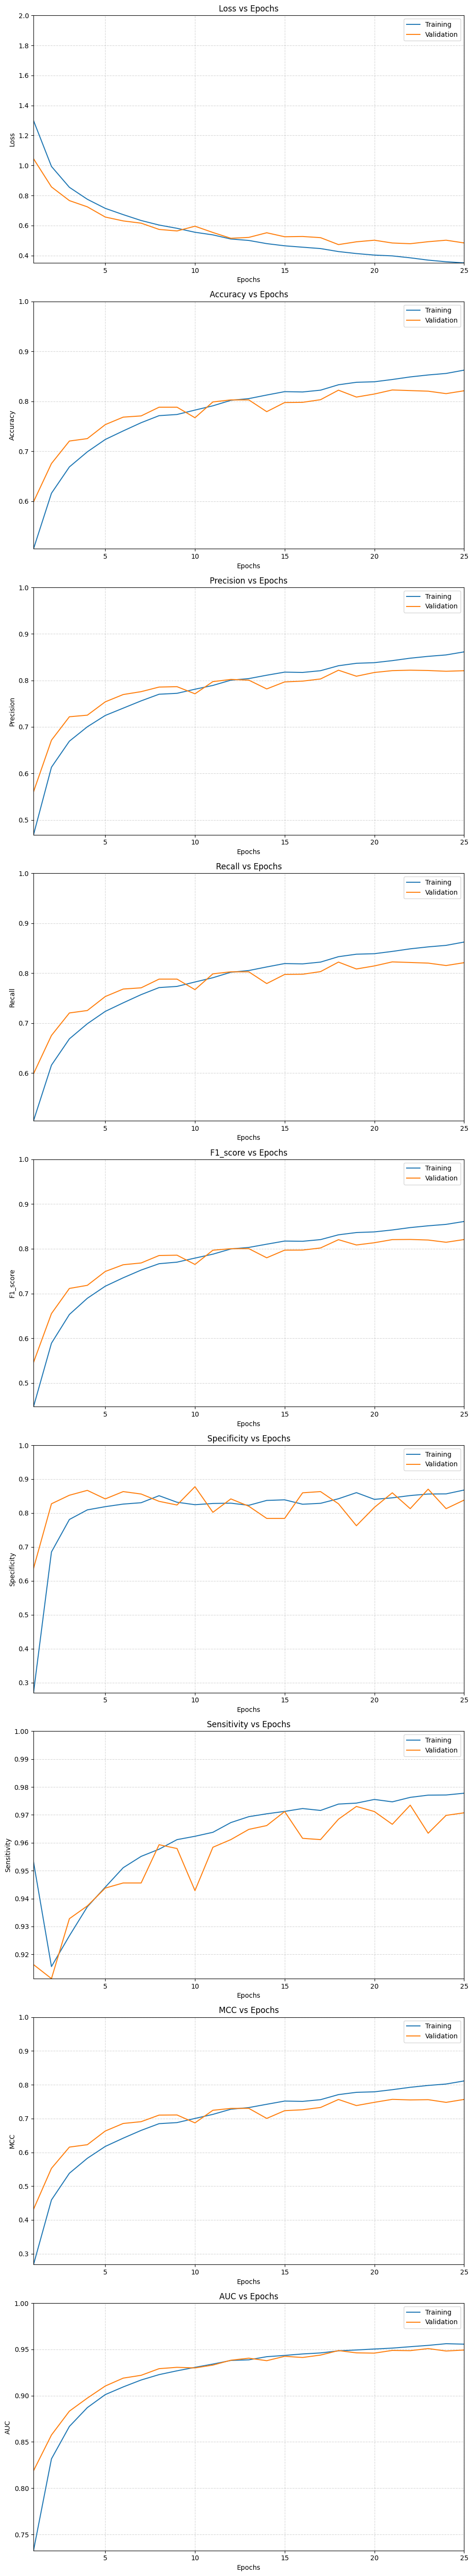

In [14]:
def plot_metrics(train_metrics_history, val_metrics_history, metric_names):
    num_metrics = len(metric_names)
    num_epochs = len(train_metrics_history[metric_names[0]])
    figure, axes = plt.subplots(num_metrics, figsize=(10, 6 * num_metrics))
    rng = range(1, num_epochs + 1)
    for ax, metric_name in zip(axes, metric_names):
        train_metric = train_metrics_history[metric_name]
        val_metric = val_metrics_history[metric_name]
        ax.plot(rng, train_metric, label="Training")
        ax.plot(rng, val_metric, label="Validation")
        ax.legend()
        ax.set_xlabel("Epochs")
        label = metric_name.upper() if metric_name in ("auc", "mcc") else metric_name.capitalize()
        ax.set_ylabel(label)
        ax.set_title(f"{label} vs Epochs")
        max_m = max(max(train_metric), max(val_metric))
        min_m = min(min(train_metric), min(val_metric))
        ax.set_ylim(min_m if min_m < 0 or max_m > 1 else min_m, math.ceil(max_m))
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.set_xlim(1, num_epochs)
    plt.tight_layout()
    plt.savefig("training_curves.png", dpi=150)
    plt.show()

plot_metrics(train_metrics_history, val_metrics_history, metric_names)

## Test Evaluation

In [15]:
model.eval()
total_loss = 0.0
all_predictions = []
all_targets = []

with torch.no_grad():
    for data, targets in tqdm(test_loader, desc="Testing Model"):
        data, targets = data.to(device), targets.to(device)
        outputs = model(data)
        loss = criterion(outputs, targets)
        total_loss += loss.item()
        all_predictions.extend(outputs.detach().cpu().numpy())
        all_targets.extend(targets.detach().cpu().numpy())

all_predictions = np.array(all_predictions)
all_targets = np.array(all_targets)
average_loss = total_loss / len(test_loader)
test_metrics = custom_metrics(torch.tensor(all_predictions), torch.tensor(all_targets), average_loss)
print("Test Metrics:")
for k, v in test_metrics.items():
    print(f"  {k}: {v:.4f}")

Testing Model: 100%|██████████| 155/155 [04:47<00:00,  1.86s/it]

Test Metrics:
  loss: 0.4887
  accuracy: 0.8122
  precision: 0.8133
  recall: 0.8122
  f1_score: 0.8125
  specificity: 0.8273
  sensitivity: 0.9675
  mcc: 0.7446
  auc: 0.9488


## Classification Report & Confusion Matrix

                     precision    recall  f1-score   support

Bacterial Pneumonia     0.7641    0.8273    0.7945       278
              COVID     0.8470    0.8564    0.8516       362
       Lung_Opacity     0.7986    0.7854    0.7919       601
             Normal     0.8554    0.8361    0.8457      1019
       Tuberculosis     0.8194    0.8429    0.8310        70
    Viral Pneumonia     0.5683    0.5852    0.5766       135

           accuracy                         0.8122      2465
          macro avg     0.7755    0.7889    0.7819      2465
       weighted avg     0.8133    0.8122    0.8125      2465

There were 463 errors in 2465 tests for an accuracy of  81.22%


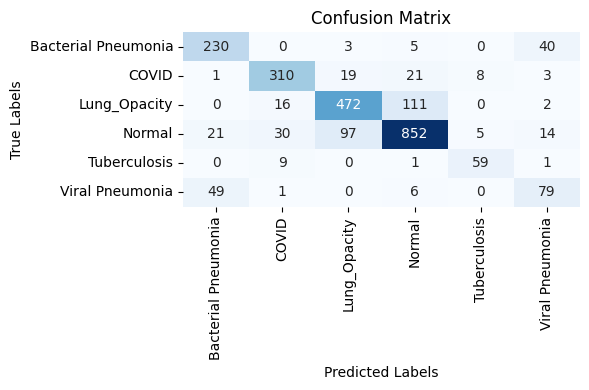

In [16]:
true_labels = np.array(all_targets).astype(int)
predicted_labels = np.argmax(np.array(all_predictions), axis=1).astype(int)
report = classification_report(true_labels, predicted_labels, target_names=classes, digits=4)
accuracy = accuracy_score(true_labels, predicted_labels)
num_errors = np.sum(true_labels != predicted_labels)
print(report)
print(f'There were {num_errors} errors in {len(predicted_labels)} tests for an accuracy of {accuracy*100:6.2f}%')

conf_matrix = torch.zeros(num_classes, num_classes)
for t, p in zip(true_labels, predicted_labels):
    conf_matrix[t, p] += 1
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False,
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.tight_layout()
plt.savefig("confusion_test.png", dpi=150)
plt.show()

## One-vs-Rest ROC Curves (test)

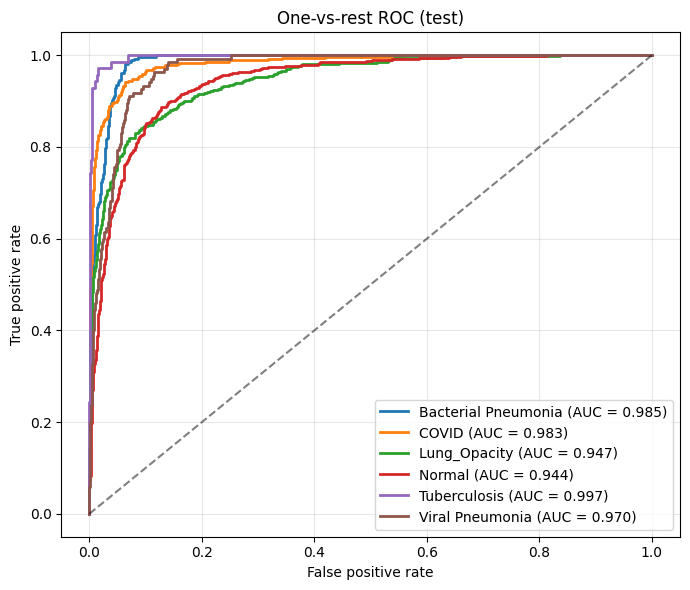

In [17]:
probs = torch.softmax(torch.tensor(all_predictions), dim=1).numpy()
plt.figure(figsize=(7, 6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve((true_labels == i).astype(int), probs[:, i])
    plt.plot(fpr, tpr, lw=2, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=.5)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("One-vs-rest ROC (test)"); plt.legend(loc="lower right"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("roc_curves.png", dpi=150); plt.show()

## (Optional) Visualise the Mobile <- Former attention

Where each of the 6 global tokens looks in a high-resolution block, for a few test images.

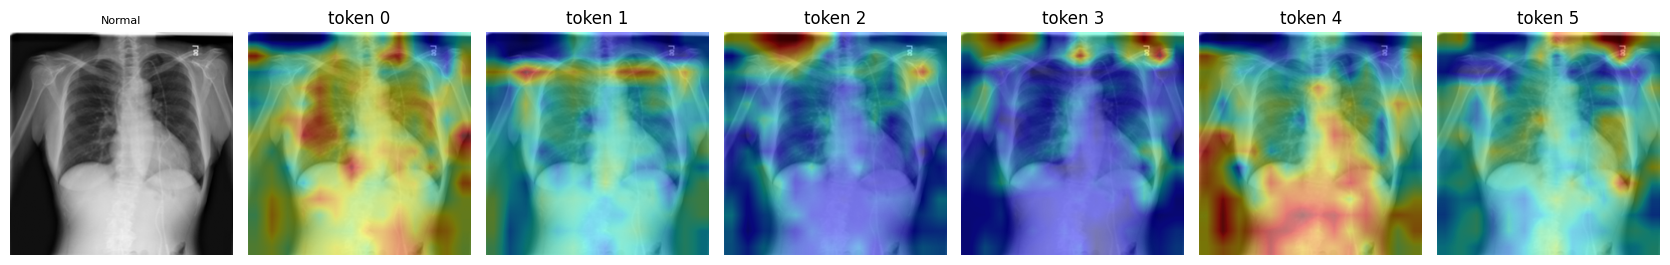

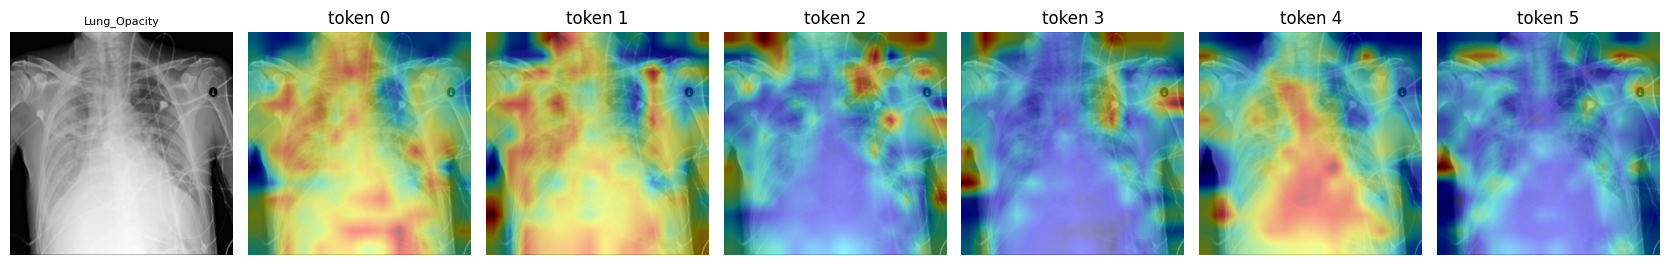

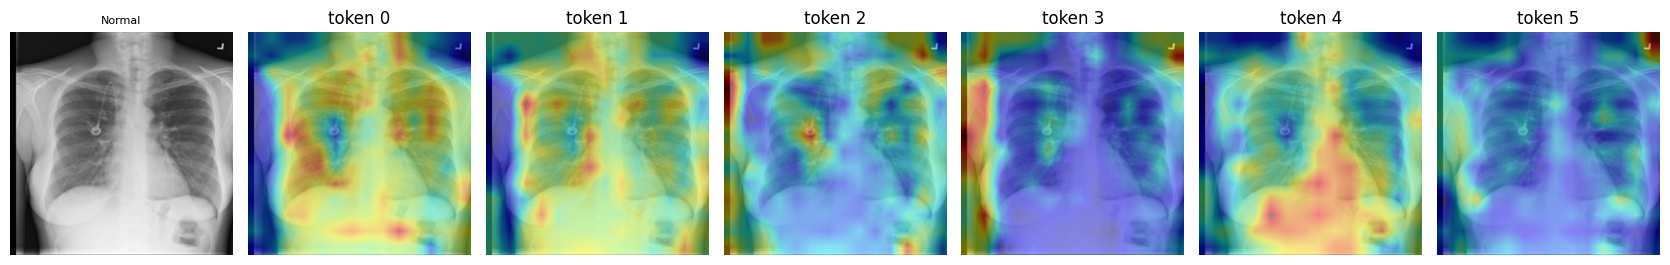

In [18]:
@torch.no_grad()
def show_token_attention(model, ds, idx, block=5):
    model.eval()
    x, y = ds[idx]
    xb = x.unsqueeze(0).to(device)
    model(xb)
    attn = model.blocks[block].f2m.last_attn[0].mean(0).cpu()       # (HW, M) averaged over heads
    hw = int(attn.shape[0] ** 0.5)
    M = attn.shape[1]
    img = (x[0] * 0.5 + 0.5).cpu()                                  # undo normalisation, show one channel
    fig, ax = plt.subplots(1, M + 1, figsize=(2.4 * (M + 1), 2.6))
    ax[0].imshow(img, cmap="gray"); ax[0].set_title(str(classes[y]), fontsize=8); ax[0].axis("off")
    for t in range(M):
        a = attn[:, t].reshape(1, 1, hw, hw)
        a = F.interpolate(a, size=img.shape[-2:], mode="bilinear")[0, 0]
        ax[t + 1].imshow(img, cmap="gray"); ax[t + 1].imshow(a, cmap="jet", alpha=0.45)
        ax[t + 1].set_title(f"token {t}"); ax[t + 1].axis("off")
    plt.tight_layout(); plt.show()

for i in [0, 1, 2]:
    show_token_attention(model, test_dataset, i)